# Modulación_QAM (8-QAM) — Laboratorio 6 COEL
Se repiten los 10 pasos de la guía para una modulación en cuadratura: **8-QAM** de dos anillos (amplitudes 0.765 y 1.848, cuatro fases a 45°/135°/225°/315°). Verificación: potencia media = (0.765² + 1.848²)/2 ≈ 2.0, es la constelación 8-QAM "star" estándar.

**Integrantes:** _(completar)_ · **Fecha:** _(completar)_

## Paso 1 · Librerías

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy
import wave

# Carpeta donde se guardan las figuras (solo si se ejecuta dentro del repositorio; en Colab se omite)
FIG_DIR = "../figures" if os.path.isdir("../figures") else None
def guardar(nombre):
    """Guarda la figura activa como PNG en figures/ (para el informe)."""
    if FIG_DIR:
        plt.savefig(f"{FIG_DIR}/{nombre}.png", dpi=150, bbox_inches="tight")

np.random.seed(42)  # semilla fija: resultados reproducibles para el informe
print("numpy", np.__version__, "| scipy", scipy.__version__)

numpy 2.5.4 | scipy 1.18.1


## Paso 2 · Constelación 8-QAM

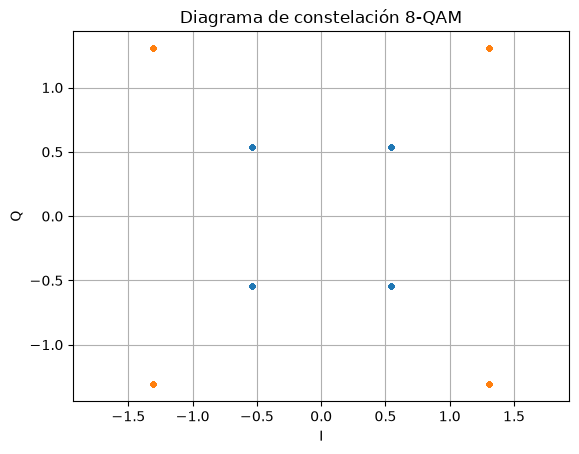

Potencia media de la constelación: 2.0001645000000003


In [2]:
num_symbols = 1000
x_int = np.random.randint(0, 4, num_symbols)          # Fase: enteros {0,1,2,3}
x_degrees = x_int*360/4.0 + 45                        # 45, 135, 225, 315 grados
x_radians = x_degrees*np.pi/180.0

A1, A2 = 0.765, 1.848                                 # Radio de los dos anillos
x_symbols  = A1*(np.cos(x_radians) + 1j*np.sin(x_radians))   # Anillo interno
x_symbols2 = A2*(np.cos(x_radians) + 1j*np.sin(x_radians))   # Anillo externo

plt.title("Diagrama de constelación 8-QAM")
plt.xlabel("I"); plt.ylabel("Q")
plt.plot(np.real(x_symbols), np.imag(x_symbols), '.')
plt.plot(np.real(x_symbols2), np.imag(x_symbols2), '.')
plt.axis('equal'); plt.grid(True); guardar("qam_01_constelacion"); plt.show()
print("Potencia media de la constelación:", (A1**2 + A2**2)/2)

## Paso 3 · Ruido AWGN
> **[CORRECCIÓN]** La guía grafica solo dos símbolos (con leyenda "Magnitud 2.62 / 1.08", valores que no corresponden a los anillos). Aquí se aplica el ruido a los **dos** anillos y se grafican los 1000 símbolos.

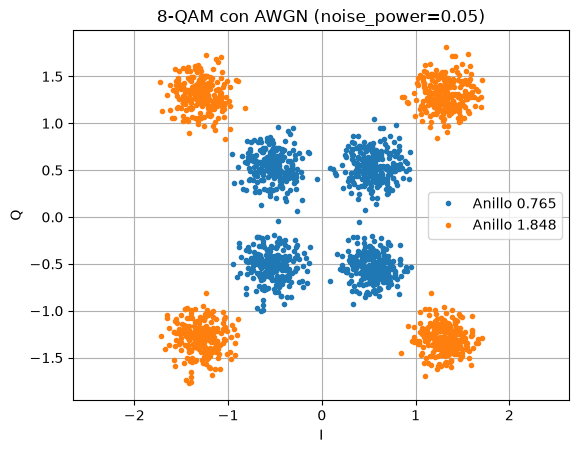

In [3]:
n = (np.random.randn(num_symbols) + 1j*np.random.randn(num_symbols))/np.sqrt(2)  # AWGN potencia unitaria
noise_power = 0.05
r1 = x_symbols  + n*np.sqrt(noise_power)              # Anillo interno + ruido
r2 = x_symbols2 + n*np.sqrt(noise_power)              # Anillo externo + ruido

plt.plot(np.real(r1), np.imag(r1), '.', label=f'Anillo {A1}')
plt.plot(np.real(r2), np.imag(r2), '.', label=f'Anillo {A2}')
plt.title(f"8-QAM con AWGN (noise_power={noise_power})")
plt.xlabel("I"); plt.ylabel("Q"); plt.axis('equal'); plt.grid(True); plt.legend()
guardar("qam_02_awgn"); plt.show()

## Paso 4 · Aumentar `noise_power` hasta que los anillos se mezclen (guía: 0.9)

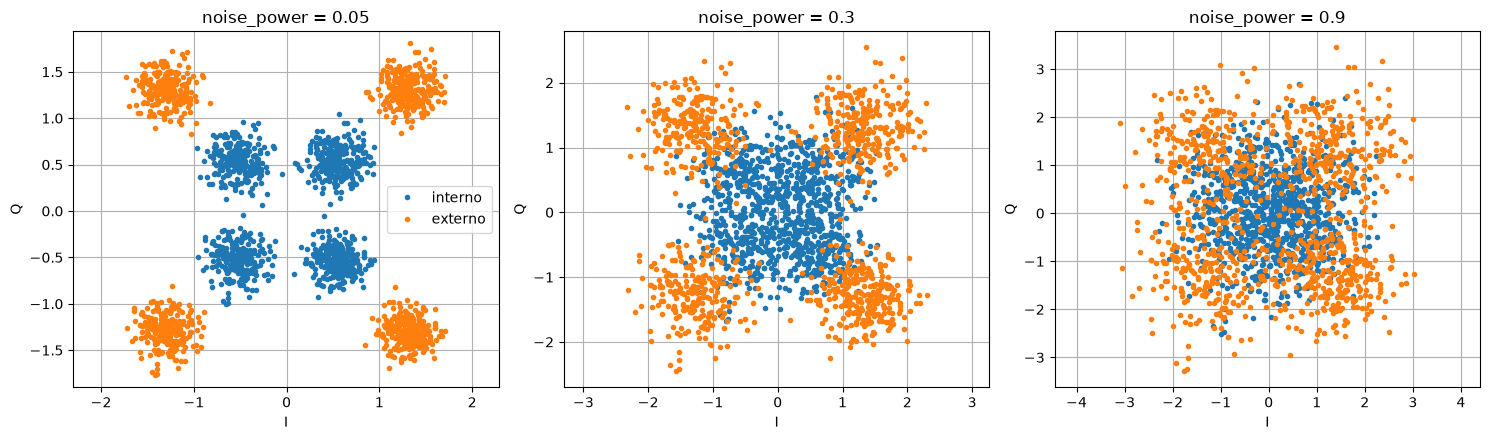

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, npow in zip(ejes, [0.05, 0.3, 0.9]):
    ra = x_symbols  + n*np.sqrt(npow)
    rb = x_symbols2 + n*np.sqrt(npow)
    ax.plot(ra.real, ra.imag, '.', label='interno'); ax.plot(rb.real, rb.imag, '.', label='externo')
    ax.set_title(f"noise_power = {npow}"); ax.set_xlabel("I"); ax.set_ylabel("Q"); ax.axis('equal'); ax.grid(True)
ejes[0].legend(); plt.tight_layout(); guardar("qam_03_barrido_ruido"); plt.show()

## Paso 5 · Ruido de fase

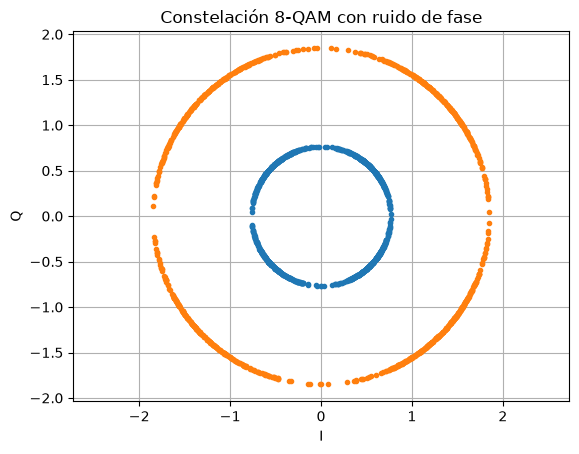

In [5]:
phase_noise = np.random.randn(len(x_symbols))*0.3     # desviación 0.3 rad
r  = x_symbols  * np.exp(1j*phase_noise)
r2 = x_symbols2 * np.exp(1j*phase_noise)

plt.title("Constelación 8-QAM con ruido de fase")
plt.xlabel("I"); plt.ylabel("Q")
plt.plot(r.real, r.imag, '.'); plt.plot(r2.real, r2.imag, '.')
plt.axis('equal'); plt.grid(True); guardar("qam_04_ruido_fase"); plt.show()

## Paso 6 · AWGN + ruido de fase simultáneos
> **[CORRECCIÓN]** La guía generaba `noise_power = 0.9` en el paso 4 y lo reutilizaba aquí (muy alto); se fija un valor explícito moderado.

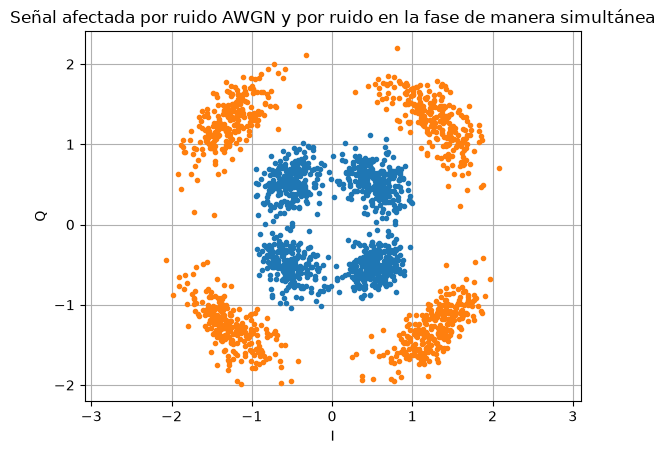

In [6]:
noise_power = 0.05
phase_noise  = np.random.randn(len(x_symbols))*0.2
phase_noise2 = np.random.randn(len(x_symbols2))*0.2

r1 = (x_symbols *np.exp(1j*phase_noise )) + n*np.sqrt(noise_power)   # Anillo interno
r2 = (x_symbols2*np.exp(1j*phase_noise2)) + n*np.sqrt(noise_power)   # Anillo externo

plt.plot(r1.real, r1.imag, '.'); plt.plot(r2.real, r2.imag, '.')
plt.title("Señal afectada por ruido AWGN y por ruido en la fase de manera simultánea")
plt.xlabel("I"); plt.ylabel("Q"); plt.axis('equal'); plt.grid(True); guardar("qam_05_awgn_fase"); plt.show()

## Paso 7 · Onda 8-QAM construida bit a bit
La guía agrupa los bits de a 3 y asigna la **amplitud** (el bit menos significativo decide el anillo). Se conserva esa función y se muestra la onda.
> **[CORRECCIÓN]** `input()` se reemplaza por una variable (así el cuaderno corre sin interacción, también en Colab). Para cambiar la secuencia basta editar `cadena_bits`.

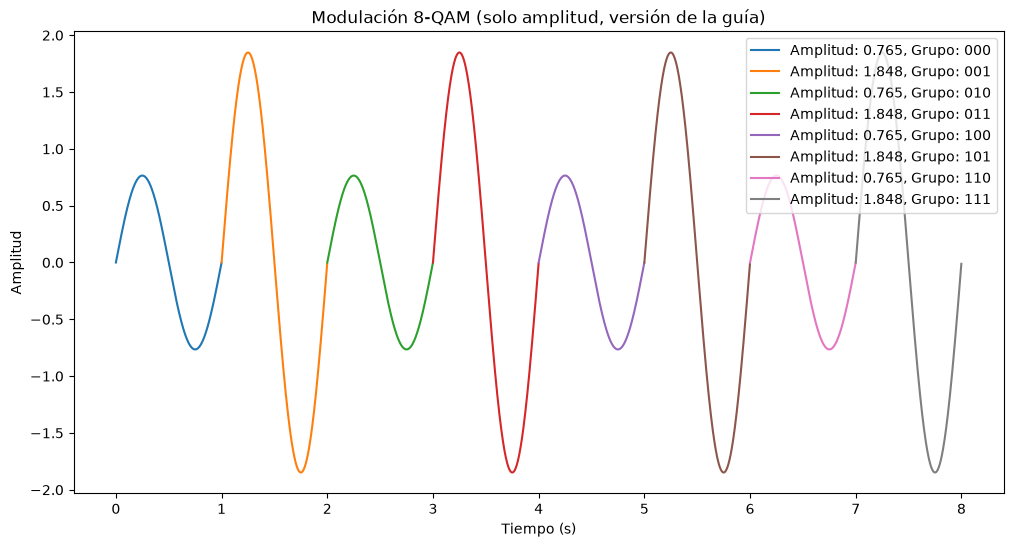

In [7]:
def agrupar_en_tres(cadena_bits):
    if len(cadena_bits) % 3 != 0:                       # Debe ser múltiplo de 3
        print("La longitud de la cadena de bits debe ser un múltiplo de 3.")
        return None
    return [cadena_bits[i:i+3] for i in range(0, len(cadena_bits), 3)]   # Grupos de 3 bits

def asignar_amplitud(bits_grupo):
    amplitudes_definidas = {'000': 0.765, '001': 1.848, '010': 0.765, '011': 1.848,
                            '100': 0.765, '101': 1.848, '110': 0.765, '111': 1.848}
    return amplitudes_definidas.get(bits_grupo, 0)      # Amplitud según el grupo

def generar_onda_seno(amplitud, frecuencia, duracion, tasa_muestreo):
    tiempo = np.arange(0, duracion, 1/tasa_muestreo)
    return tiempo, amplitud*np.sin(2*np.pi*frecuencia*tiempo)

def plotear_ondas_seno(secuencia_bits, tasa_muestreo=1000):
    plt.figure(figsize=(12, 6))
    for i, grupo in enumerate(secuencia_bits):
        amplitud = asignar_amplitud(grupo)
        tiempo, onda = generar_onda_seno(amplitud, 1, 1, tasa_muestreo)
        plt.plot(tiempo + i*1, onda, label=f'Amplitud: {amplitud}, Grupo: {grupo}')   # Cada grupo 1 s, una tras otra
    plt.title("Modulación 8-QAM (solo amplitud, versión de la guía)")
    plt.xlabel("Tiempo (s)"); plt.ylabel("Amplitud"); plt.legend(); guardar("qam_06_onda_guia"); plt.show()

cadena_bits = "000001010011100101110111"                # Edite aquí (múltiplo de 3). Alternativa: input("Bits: ")
plotear_ondas_seno(agrupar_en_tres(cadena_bits))

### Versión completa 8-QAM (amplitud **y** fase)
La función de la guía solo usa la amplitud, así que dos grupos distintos con igual amplitud producen la misma onda (no se distinguen los 8 símbolos). Aquí un bit elige el anillo y dos bits la fase (Gray), y la portadora se construye como `Re{ s·e^{jωt} } = I·cos(ωt) − Q·sin(ωt)`, que es lo que hace el bloque *QAM Mod* de GNU Radio.

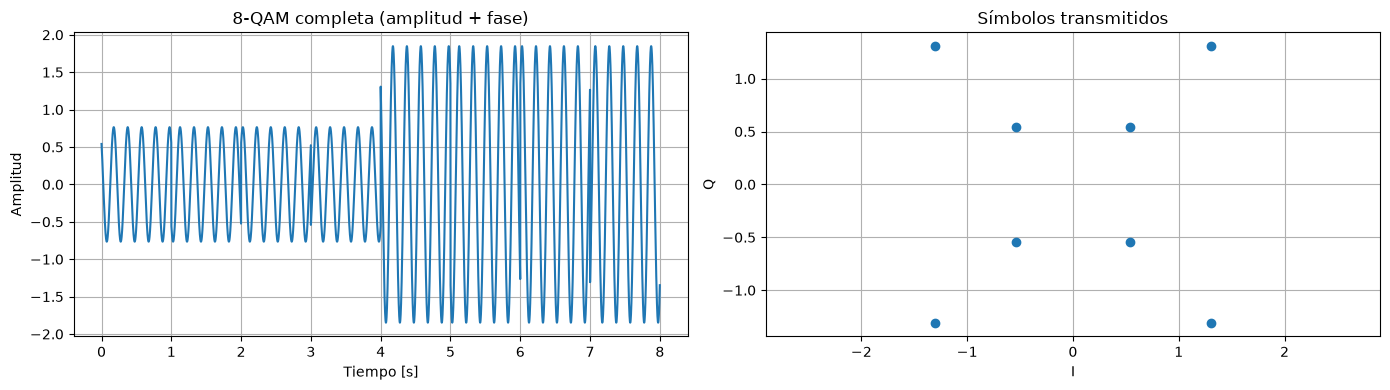

In [8]:
GRAY = {'00': 45, '01': 135, '11': 225, '10': 315}   # Mapeo Gray de 2 bits a fase (grados)

def mapear_8qam(grupo):
    """3 bits -> símbolo complejo. bit0: anillo (0 interno, 1 externo); bits1-2: fase Gray."""
    radio = A2 if grupo[0] == '1' else A1
    return radio*np.exp(1j*np.deg2rad(GRAY[grupo[1:]]))

def modular_8qam(cadena, fc=5, baud=1, fs=1000):
    simbolos = np.array([mapear_8qam(g) for g in agrupar_en_tres(cadena)])
    sps = int(fs/baud)                                   # muestras por símbolo
    t = np.arange(len(simbolos)*sps)/fs
    s = np.repeat(simbolos, sps)                         # símbolo mantenido durante T
    return t, np.real(s*np.exp(2j*np.pi*fc*t)), simbolos

t, x, simbolos = modular_8qam(cadena_bits)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4))
a.plot(t, x); a.set_title("8-QAM completa (amplitud + fase)"); a.set_xlabel("Tiempo [s]"); a.set_ylabel("Amplitud"); a.grid(True)
b.plot(simbolos.real, simbolos.imag, 'o'); b.set_title("Símbolos transmitidos"); b.set_xlabel("I"); b.set_ylabel("Q"); b.axis('equal'); b.grid(True)
plt.tight_layout(); guardar("qam_07_onda_completa"); plt.show()

## Pasos 8–10 · Demodulación, conteo de errores y exportación
Se agrega ruido blanco a la señal modulada (el integrador promedia 1000 muestras por símbolo, por eso `sigma` debe ser grande para ver errores), se demodula coherentemente (multiplicar por `cos` y `−sin` e integrar por símbolo) y se mide la BER.

ruido sigma = 0.0  -> BER = 0.0000
ruido sigma = 5.0  -> BER = 0.0017
ruido sigma = 10.0 -> BER = 0.0675
ruido sigma = 20.0 -> BER = 0.2233
ruido sigma = 40.0 -> BER = 0.3500


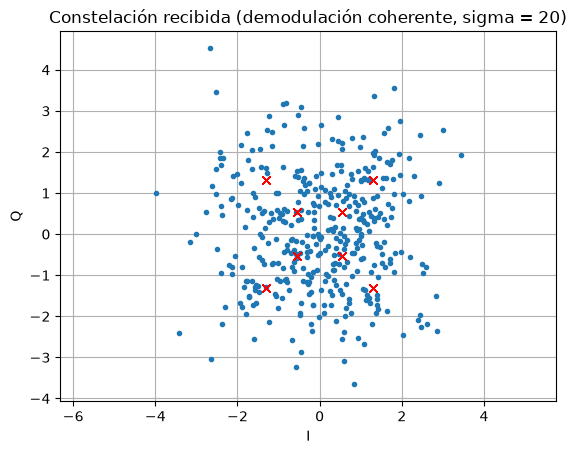

escrito: ../data/mensaje_qam.wav


In [9]:
def demodular_8qam(x, fc=5, baud=1, fs=1000):
    sps = int(fs/baud); t = np.arange(len(x))/fs
    I = (2*x*np.cos(2*np.pi*fc*t)).reshape(-1, sps).mean(axis=1)    # Rama en fase
    Q = (-2*x*np.sin(2*np.pi*fc*t)).reshape(-1, sps).mean(axis=1)   # Rama en cuadratura
    return I + 1j*Q

def decidir(rx):
    """Decisión por mínima distancia a los 8 puntos de la constelación."""
    pts = {g: mapear_8qam(g) for g in ['000','001','010','011','100','101','110','111']}
    return ''.join(min(pts, key=lambda g: abs(s - pts[g])) for s in rx)

bits_tx = ''.join(np.random.choice(['0', '1'], 3*400))               # 400 símbolos aleatorios
t, xt, simb = modular_8qam(bits_tx)
for sigma in [0.0, 5.0, 10.0, 20.0, 40.0]:
    rx = demodular_8qam(xt + sigma*np.random.randn(len(xt)))
    bits_rx = decidir(rx)
    ber = np.mean([a != b for a, b in zip(bits_tx, bits_rx)])
    print(f"ruido sigma = {sigma:<4} -> BER = {ber:.4f}")
    if sigma == 20.0:
        rx_plot = rx
plt.plot(rx_plot.real, rx_plot.imag, '.'); plt.plot(simb.real, simb.imag, 'rx')
plt.title("Constelación recibida (demodulación coherente, sigma = 20)"); plt.xlabel("I"); plt.ylabel("Q")
plt.axis('equal'); plt.grid(True); guardar("qam_08_constelacion_rx"); plt.show()

# Exportación a .wav (la guía recomienda este formato)
t, xw, _ = modular_8qam("000001010011100101110111", fc=1000, baud=100, fs=48000)
ruta = "../data/mensaje_qam.wav" if os.path.isdir("../data") else "mensaje_qam.wav"
with wave.open(ruta, "wb") as w:
    w.setnchannels(1); w.setsampwidth(2); w.setframerate(48000)
    w.writeframes((xw/np.max(np.abs(xw))*0.8*32767).astype(np.int16).tobytes())
print("escrito:", ruta)